In [1]:
import numpy as np
from numpy.random import normal
import matplotlib.pyplot as plt

import sys
sys.path.append(r'C:\Users\Admin\python data\GitHub\Gravity7D')
from qgravity import (
    EulerMaruyama,
    ItoSolver,
    OrnsteinUhlenbeck,
    QuadraticGravity,
    TrajectoryEnsemble,
    Scale_factor_calculator,
    Gravity7D,
    Gravity_7D
)


In [2]:
TOTAL_TAU = 4
TAU_STEP = 10 ** -6
N_SAMPLES = 10
N_T_POINTS = 100

RNG = np.random.default_rng(42)

Sigma = 0.05
epsilon = 0.1 
model7 = Gravity7D(sigma=Sigma,eps=epsilon)

solver7 = ItoSolver(model7,EulerMaruyama(),TAU_STEP,TOTAL_TAU,RNG)


ens7 = TrajectoryEnsemble(solver7,np.array([1.0,1.0,0.0,0.0,-epsilon/14,0.0]),(1,2))
trajs7 = ens7.solve_many(N_SAMPLES)
calculator7 = Scale_factor_calculator(trajs7,N_T_POINTS)
t7, a7, std7 = calculator7.calculate_statistics()

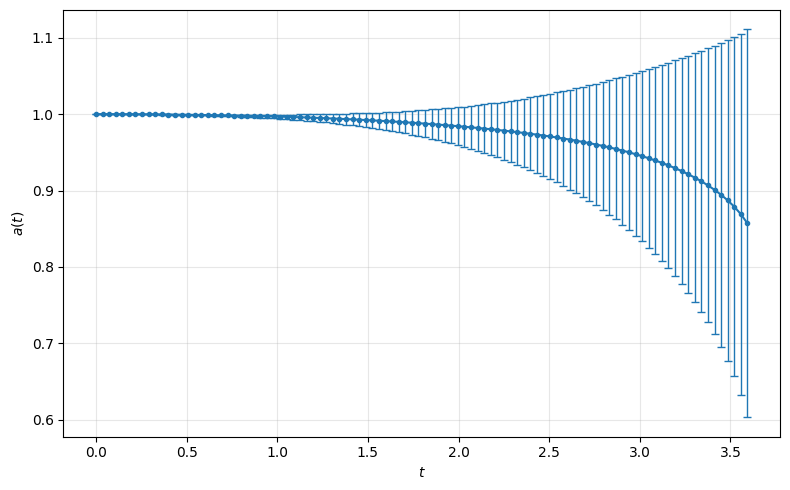

In [3]:
def plot_with_errors(x, y, y_err, xlabel="x", ylabel="y"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.errorbar(
        x, y,
        yerr=y_err,
        fmt="-o",
        markersize=3,
        capsize=3,
        elinewidth=1,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    fig.tight_layout()

    return fig, ax


# Для результата Scale_factor_calculator:
fig, ax = plot_with_errors(
    t7, a7, std7,
    xlabel=r"$t$",
    ylabel=r"$a(t)$",
)
plt.show()


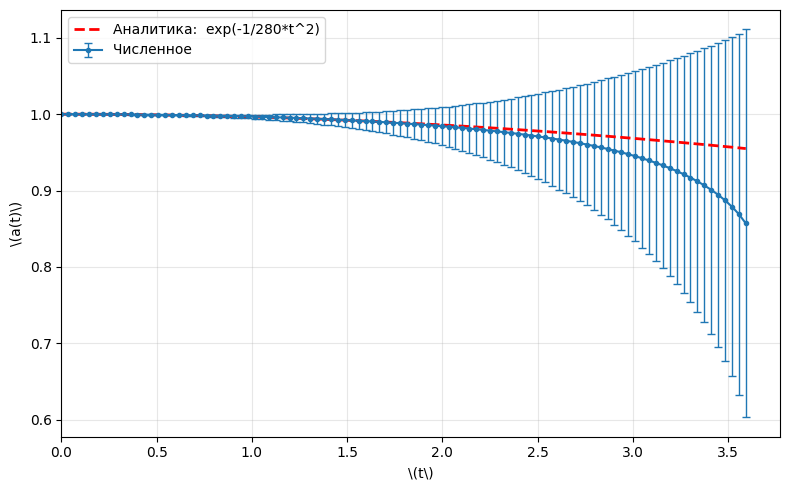

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def plot_with_errors(x, y, y_err, xlabel="x", ylabel="y", label=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(
        x, y,
        yerr=y_err,
        fmt="-o",
        markersize=3,
        capsize=3,
        elinewidth=1,
        label=label
    )
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig, ax

# --- Параметры для аналитики ---
       # Начальное значение (при t=0)
 

# Считаем аналитическое решение
a_analytical =  np.exp(-epsilon/28 * t7**2)

# --- Построение графика ---
fig, ax = plot_with_errors(
    t7, a7, std7,
    xlabel=r"\(t\)",
    ylabel=r"\(a(t)\)",
    label="Численное "
)

# Накладываем аналитическую кривую
ax.plot(t7, a_analytical, 'r--', linewidth=2, label=r"Аналитика:  exp(-1/280*t^2)")

ax.set_xlim(left=0)
ax.legend()
plt.show()